In [ ]:
# install the required labraries
!pip install transformers datasets scikit-learn torch -q

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import torch
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)
from datasets import Dataset

print(f"Libraries imported")
print(f"Device : {'GPU ' if torch.cuda.is_available() else 'CPU '}")

Libraries imported
Device : GPU 


In [ ]:
# load the train data and the test data from the drive

from google.colab import drive
drive.mount('/content/drive')

train_data = pd.read_csv("/content/drive/MyDrive/train_data.csv")
test_data = pd.read_csv("/content/drive/MyDrive/test_data.csv")

In [ ]:
# data overview
print(f"Train : {len(train_data)} rows")
print(f"Test  : {len(test_data)} rows")
print(f"\n Train sentiment :\n{train_data['sentiment'].value_counts()}")

Train : 3359 rows
Test  : 840 rows

 Train sentiment :
sentiment
neutral     1203
positive    1105
negative    1051
Name: count, dtype: int64


In [ ]:
# convert sentiment labels to numbers
label2id = {
    "negative" : 0,
    "neutral" : 1,
    "positive" : 2
}

id2label = {
    0 : "negative",
    1 : "neutral",
    2 : "positive"
}

train_data["label"] = train_data["sentiment"].map(label2id)
test_data["label"] = test_data["sentiment"].map(label2id)



In [ ]:
# chose the model to fine-tune
# option 2 : "bert-base-multilingual-cased"

MODEL_NAME = "bert-base-multilingual-cased"
print(f"Model : {MODEL_NAME}")

Model : bert-base-multilingual-cased


In [ ]:
# load the tokenizer
toknizer= AutoTokenizer.from_pretrained(MODEL_NAME)

# test the toknizer on the data smaple
sample = train_data["text"].iloc[1]
print(f"Sample : {sample}")

In [ ]:
tokens = toknizer(sample, return_tensors="pt")
print(f"Tokens : {tokens}")
print(f"Tokenizer loaded : {MODEL_NAME}")
print(f"Token IDs   : {tokens['input_ids']}")
print(f"Num tokens  : {tokens['input_ids'].shape[1]}")

In [ ]:
# toknize the data
# we will take as a max  token per text 128 , because our text average is 9 words, so 128 is enough
MAX_LENGTH = 128
def toknize_function(examples):
    return toknizer(examples["text"], padding="max_length", truncation=True, max_length=MAX_LENGTH)


# convert to hugging face dataset format
train_dataset = Dataset.from_pandas(train_data[["text", "label"]])
test_dataset = Dataset.from_pandas(test_data[["text", "label"]])

# apply the toknizer
train_dataset = train_dataset.map(toknize_function, batched=True)
test_dataset = test_dataset.map(toknize_function, batched=True)

# printing

print(f"Train dataset tokenized : {len(train_dataset)} samples")
print(f"Test dataset tokenized  : {len(test_dataset)} samples")
print(f"\nDataset features : {train_dataset.features}")


In [ ]:
# load model "mBERT"
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3, # positive , negative and neutral
    id2label = id2label,
    label2id = label2id
)

print(f"Model loaded : {MODEL_NAME}")
print(f"Number of labels : 3")
print(f"Labels : {id2label}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded : bert-base-multilingual-cased
Number of labels : 3
Labels : {0: 'negative', 1: 'neutral', 2: 'positive'}


In [ ]:
# define the metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)
    f1_macro = f1_score(labels, predictions, average="macro")
    f1_weighted = f1_score(labels, predictions, average="weighted")

    return {
        "accuracy" : accuracy,
        "f1_macro" : f1_macro,
        "f1_weighted" : f1_weighted
    }
print(f"Metrics defined : accuracy, f1_macro, f1_weighted")

Metrics defined : accuracy, f1_macro, f1_weighted


In [ ]:
import transformers
print(transformers.__version__)

5.12.1


In [ ]:
# define training arguments
OUTPUT_DIR = "/content/drive/MyDrive/results/mbert-base-v3"

training_args = TrainingArguments(
    output_dir          = OUTPUT_DIR,
    #num_train_epochs    = 5, # to avoid overfintign
    num_train_epochs    = 3,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 16,
    learning_rate       = 1e-5,
    weight_decay        = 0.01,
    eval_strategy="epoch",
    save_strategy       = "epoch",
    load_best_model_at_end = True,
    metric_for_best_model  = "f1_macro",
    logging_dir         = "./logs",
    logging_steps       = 50,
    warmup_steps        = 100,
    fp16                = torch.cuda.is_available(),  # use GPU if available
    report_to           = "none"
)

print(f" Training arguments defined")
print(f" Epochs      : 3")
print(f" Batch size  : 16")
print(f" LR          : 1e-5")

[transformers] `logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


 Training arguments defined
 Epochs      : 3
 Batch size  : 16
 LR          : 1e-5


In [ ]:
# Train the model
trainer = Trainer(
    model           = model,
    args            = training_args,
    train_dataset   = train_dataset,
    eval_dataset    = test_dataset,
    compute_metrics = compute_metrics,
    callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)]
)

print(f" Starting fine-tuning : {MODEL_NAME}")
print(f" This may take a few minutes...")

trainer.train()

print(f"\n Fine-tuning completed !")

 Starting fine-tuning : bert-base-multilingual-cased
 This may take a few minutes...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.641624,0.578518,0.777381,0.779624,0.779647
2,0.446958,0.486218,0.817857,0.818181,0.817973
3,0.366029,0.473979,0.834524,0.834107,0.833932


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


 Fine-tuning completed !


In [ ]:
#  Evaluate on test set
results = trainer.evaluate(test_dataset)

print(f" EVALUATION RESULTS — {MODEL_NAME}")
print(f"{'-'*45}")
print(f" Accuracy    : {results['eval_accuracy']:.4f}")
print(f" F1 Macro    : {results['eval_f1_macro']:.4f}")
print(f" F1 Weighted : {results['eval_f1_weighted']:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Weighted
0.366029,0.473979,3,0.834524,0.834107,0.833932


 EVALUATION RESULTS — bert-base-multilingual-cased
---------------------------------------------
 Accuracy    : 0.8345
 F1 Macro    : 0.8341
 F1 Weighted : 0.8339


In [ ]:
#  Save model and tokenizer directly on Google Drive
SAVE_PATH = "/content/drive/MyDrive/results/mbert-finetuned-v3"

model.save_pretrained(SAVE_PATH)
toknizer.save_pretrained(SAVE_PATH)

print(f" Model saved → {SAVE_PATH}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 Model saved → /content/drive/MyDrive/results/mbert-finetuned-v3


In [ ]:
#  Detailed classification report
predictions = trainer.predict(test_dataset)
pred_labels = np.argmax(predictions.predictions, axis=-1)
true_labels = test_data["label"].values

# report = classification_report(
#     true_labels,
#     pred_labels,
#     target_names=["positive", "negative", "neutral"]
# )
report = classification_report(
    true_labels, pred_labels,
    target_names=["negative", "neutral", "positive"]  # the same order label2id
)

print(f" CLASSIFICATION REPORT — {MODEL_NAME}")
print(f"{'-'*45}")
print(report)



 CLASSIFICATION REPORT — bert-base-multilingual-cased
---------------------------------------------
              precision    recall  f1-score   support

    negative       0.83      0.73      0.78       263
     neutral       0.77      0.84      0.80       301
    positive       0.92      0.93      0.92       276

    accuracy                           0.83       840
   macro avg       0.84      0.83      0.83       840
weighted avg       0.84      0.83      0.83       840



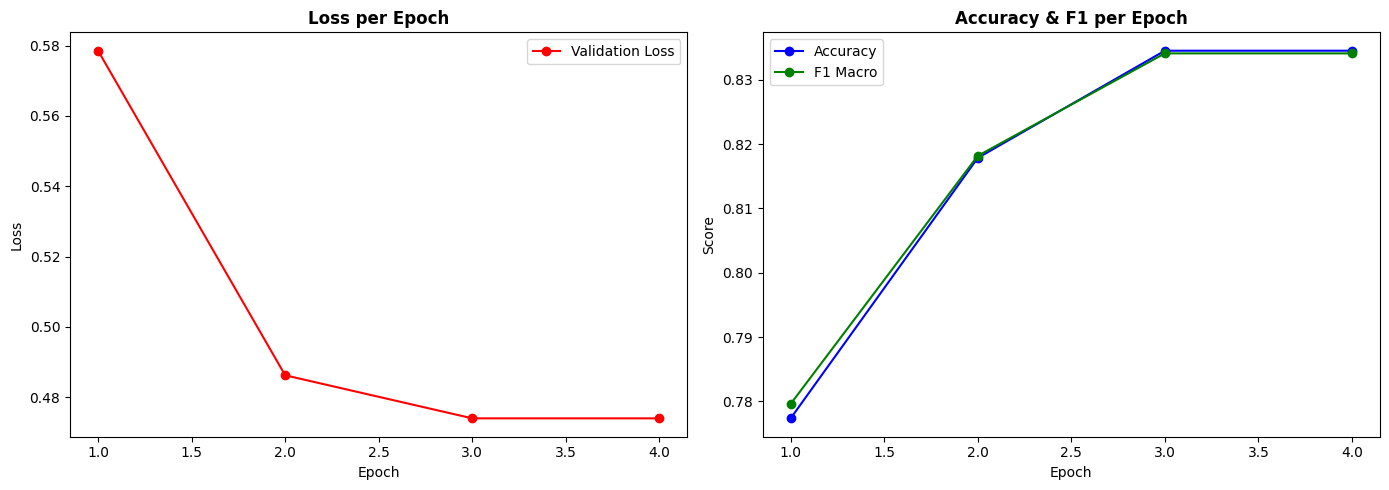

In [ ]:
#  Plot training curves
import matplotlib.pyplot as plt

log_history = trainer.state.log_history

train_loss = [x["loss"] for x in log_history if "loss" in x]
eval_loss  = [x["eval_loss"] for x in log_history if "eval_loss" in x]
accuracy   = [x["eval_accuracy"] for x in log_history if "eval_accuracy" in x]
f1         = [x["eval_f1_macro"] for x in log_history if "eval_f1_macro" in x]
epochs     = list(range(1, len(eval_loss)+1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(epochs, eval_loss, 'r-o', label="Validation Loss")
axes[0].set_title("Loss per Epoch", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Accuracy + F1
axes[1].plot(epochs, accuracy, 'b-o', label="Accuracy")
axes[1].plot(epochs, f1, 'g-o', label="F1 Macro")
axes[1].set_title("Accuracy & F1 per Epoch", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/results/training_curves_mbert.png", dpi=150)
plt.show()